# Entanglement Generation — GHZ State — Qiskit Implementation

**Primitive:** GHZ-state generation (maximal 3-qubit entanglement) via H + CNOT chain

**SETUP (assumed defaults — edit below if your report needs different values)**
- N QUBITS: 3
- GATE SEQUENCE: H(q0), then CX(control=q0, target=q1), then CX(control=q1, target=q2)
- QUBIT ORDERING: qubit 0 = rightmost bit in printed bitstring (Qiskit's native convention)
- SHOTS: 10000, SEED: 42
- GLOBAL PHASE: normalized so first nonzero amplitude (ascending bitstring order) is real and positive
- Basis ordering for matrices: {|000>, |001>, ..., |111>} (ascending binary order)

**Theory recap:** Starting from |000>, a Hadamard on qubit 0 creates the superposition
(|000> + |001>)/sqrt(2). The CX chain then propagates that superposition outward: CX(q0,q1)
correlates qubit 1 with qubit 0, and CX(q1,q2) correlates qubit 2 with qubit 1, leaving all
three qubits perfectly correlated in the GHZ state

|GHZ> = (|000> + |111>) / sqrt(2)

This is a genuinely 3-body entangled state: no pair of qubits can be described without the
third, unlike a Bell pair. Measuring any one qubit instantly fixes the outcome of the other two.

H = (1/sqrt(2)) [[1, 1], [1, -1]]

CX(control, target) flips the target qubit's amplitude pairs conditioned on the control being |1>.

**IMPORTANT: Run every cell in order, top to bottom** (Kernel -> Restart & Run All).

In [1]:
# Run this cell first if you get ModuleNotFoundError or MissingOptionalLibraryError.
# pylatexenc is required for circuit.draw(output="mpl") gate-label rendering -- not pulled in
# automatically by the base qiskit install, so it must be listed explicitly.
!pip install -q qiskit qiskit-aer pylatexenc
# Restart the kernel after this finishes (Kernel -> Restart Kernel), then Run All.


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 162.6/162.6 kB 6.7 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.8/9.8 MB 41.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 33.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 29.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.5/54.5 kB 2.0 MB/s eta 0:00:00


In [2]:
# --- Imports ---
import numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector, Operator
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram

# --- SETUP constants (all cells below use these -- defined once, here) ---
N_QUBITS = 3
SHOTS = 10000
SEED = 42

print(f"N_QUBITS={N_QUBITS}, SHOTS={SHOTS}, SEED={SEED}")
print("Gate sequence: H(q0) -> CX(control=q0, target=q1) -> CX(control=q1, target=q2)")

N_QUBITS=3, SHOTS=10000, SEED=42
Gate sequence: H(q0) -> CX(control=q0, target=q1) -> CX(control=q1, target=q2)


## 1. Build the circuit explicitly, gate by gate

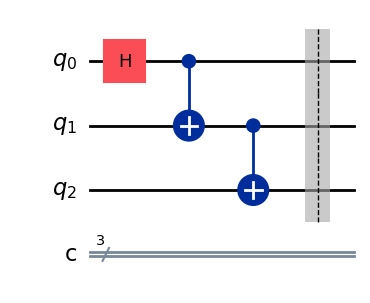

In [3]:
qc = QuantumCircuit(N_QUBITS, N_QUBITS, name="ghz_state")

qc.h(0)      # Put qubit 0 into an equal superposition of |0> and |1>
qc.cx(0, 1)  # Entangle qubit 1 with qubit 0: flip q1 whenever q0 is |1>
qc.cx(1, 2)  # Propagate the correlation to qubit 2: flip q2 whenever q1 is |1>

qc.barrier()
qc.draw(output="mpl")

## 2. Draw the circuit and save to file

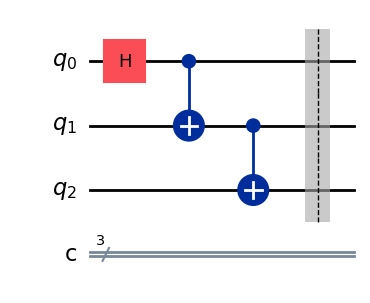

In [4]:
fig = qc.draw(output="mpl")
fig.savefig("ghz_state_qiskit_circuit.png", bbox_inches="tight")
fig

## 3. Explicit matrix representation of the key operator(s)

In [5]:
# --- (a) Hand-built full unitary via generic gate-embedding functions (Qiskit's little-endian
# convention: qubit i occupies bit position i of the basis index, qubit 0 = rightmost/LSB) ---
H_gate = (1 / np.sqrt(2)) * np.array([[1, 1],
                                       [1, -1]], dtype=complex)
print("H matrix:")
print(np.round(H_gate, 4))

def apply_1q(state, gate, q, n):
    """Apply a single-qubit gate matrix to qubit q of an n-qubit statevector."""
    dim = 2 ** n
    new = np.zeros(dim, dtype=complex)
    for idx in range(dim):
        bit = (idx >> q) & 1
        base = idx & ~(1 << q)
        for new_bit in range(2):
            amp = gate[new_bit, bit]
            if amp == 0:
                continue
            new[base | (new_bit << q)] += amp * state[idx]
    return new

def apply_cx(state, control, target, n):
    """Apply a CNOT (control, target) to an n-qubit statevector."""
    dim = 2 ** n
    new = np.zeros(dim, dtype=complex)
    for idx in range(dim):
        out_idx = idx ^ (1 << target) if (idx >> control) & 1 else idx
        new[out_idx] = state[idx]
    return new

def run_circuit_statevector(initial_state, n):
    state = initial_state.copy()
    state = apply_1q(state, H_gate, 0, n)
    state = apply_cx(state, 0, 1, n)
    state = apply_cx(state, 1, 2, n)
    return state

dim = 2 ** N_QUBITS
U_hand = np.zeros((dim, dim), dtype=complex)
for col in range(dim):
    basis = np.zeros(dim, dtype=complex)
    basis[col] = 1
    U_hand[:, col] = run_circuit_statevector(basis, N_QUBITS)

print(f"\nFull {dim}x{dim} circuit unitary U (hand-built, basis {{|000>,...,|111>}}):")
print(np.round(U_hand, 4))

unitary_ok = np.allclose(U_hand.conj().T @ U_hand, np.eye(dim), atol=1e-8)
print(f"\nU is unitary (U-dagger . U == I): {unitary_ok}")
assert unitary_ok, "Hand-built matrix is not unitary -- gate embedding logic has a bug!"

H matrix:
[[ 0.7071+0.j  0.7071+0.j]
 [ 0.7071+0.j -0.7071+0.j]]

Full 8x8 circuit unitary U (hand-built, basis {|000>,...,|111>}):
[[ 0.7071+0.j  0.7071+0.j  0.    +0.j  0.    +0.j  0.    +0.j  0.    +0.j
   0.    +0.j  0.    +0.j]
 [ 0.    +0.j  0.    +0.j  0.7071+0.j -0.7071+0.j  0.    +0.j  0.    +0.j
   0.    +0.j  0.    +0.j]
 [ 0.    +0.j  0.    +0.j  0.    +0.j  0.    +0.j  0.    +0.j  0.    +0.j
   0.7071+0.j  0.7071+0.j]
 [ 0.    +0.j  0.    +0.j  0.    +0.j  0.    +0.j  0.7071+0.j -0.7071+0.j
   0.    +0.j  0.    +0.j]
 [ 0.    +0.j  0.    +0.j  0.    +0.j  0.    +0.j  0.7071+0.j  0.7071+0.j
   0.    +0.j  0.    +0.j]
 [ 0.    +0.j  0.    +0.j  0.    +0.j  0.    +0.j  0.    +0.j  0.    +0.j
   0.7071+0.j -0.7071+0.j]
 [ 0.    +0.j  0.    +0.j  0.7071+0.j  0.7071+0.j  0.    +0.j  0.    +0.j
   0.    +0.j  0.    +0.j]
 [ 0.7071+0.j -0.7071+0.j  0.    +0.j  0.    +0.j  0.    +0.j  0.    +0.j
   0.    +0.j  0.    +0.j]]

U is unitary (U-dagger . U == I): True


In [6]:
# --- (b) Cross-check against Qiskit's own Operator extraction ---
# Operator() safely ignores barrier instructions, so qc (h + cx + cx + barrier, no measurements
# yet at this point in the notebook) can be used directly.
full_op = Operator(qc)

print(f"Full {dim}x{dim} operator from Qiskit's Operator(qc):")
print(np.round(full_op.data, 4))

matches = np.allclose(full_op.data, U_hand, atol=1e-8)
print(f"\nHand-built matrix matches Qiskit's Operator extraction: {matches}")
assert matches, "Hand-built matrix and Qiskit Operator disagree -- check gate/basis conventions!"

Full 8x8 operator from Qiskit's Operator(qc):
[[ 0.7071+0.j  0.7071+0.j  0.    +0.j  0.    +0.j  0.    +0.j  0.    +0.j
   0.    +0.j  0.    +0.j]
 [ 0.    +0.j  0.    +0.j  0.7071+0.j -0.7071+0.j  0.    +0.j  0.    +0.j
   0.    +0.j  0.    +0.j]
 [ 0.    +0.j  0.    +0.j  0.    +0.j  0.    +0.j  0.    +0.j  0.    +0.j
   0.7071+0.j  0.7071+0.j]
 [ 0.    +0.j  0.    +0.j  0.    +0.j  0.    +0.j  0.7071+0.j -0.7071+0.j
   0.    +0.j  0.    +0.j]
 [ 0.    +0.j  0.    +0.j  0.    +0.j  0.    +0.j  0.7071+0.j  0.7071+0.j
   0.    +0.j  0.    +0.j]
 [ 0.    +0.j  0.    +0.j  0.    +0.j  0.    +0.j  0.    +0.j  0.    +0.j
   0.7071+0.j -0.7071+0.j]
 [ 0.    +0.j  0.    +0.j  0.7071+0.j  0.7071+0.j  0.    +0.j  0.    +0.j
   0.    +0.j  0.    +0.j]
 [ 0.7071+0.j -0.7071+0.j  0.    +0.j  0.    +0.j  0.    +0.j  0.    +0.j
   0.    +0.j  0.    +0.j]]

Hand-built matrix matches Qiskit's Operator extraction: True


## 4. Exact statevector (before measurement), global-phase normalized

In [7]:
sv = Statevector.from_instruction(qc)  # qc has no measurements yet at this point -- safe to use directly
amps = sv.data.copy()

def normalize_global_phase(statevector_data, n_qubits):
    dim = 2 ** n_qubits
    bitstrings = [format(i, f"0{n_qubits}b") for i in range(dim)]
    order = np.argsort(bitstrings)
    for idx in order:
        amp = statevector_data[idx]
        if abs(amp) > 1e-9:
            phase = np.angle(amp)
            corrected = statevector_data * np.exp(-1j * phase)
            return corrected, bitstrings
    return statevector_data, bitstrings

amps_norm, bitstrings = normalize_global_phase(amps, N_QUBITS)

exact_probs = {}
for i, bs in enumerate(bitstrings):
    exact_probs[bs] = round(abs(amps_norm[i]) ** 2, 4)

exact_probs = dict(sorted(exact_probs.items()))
print("Exact statevector amplitudes (phase-normalized):")
print(np.round(amps_norm, 4))
print()
print("Exact statevector probabilities (qubit0 = rightmost):")
print(exact_probs)

Exact statevector amplitudes (phase-normalized):
[0.7071+0.j 0.    +0.j 0.    +0.j 0.    +0.j 0.    +0.j 0.    +0.j
 0.    +0.j 0.7071+0.j]

Exact statevector probabilities (qubit0 = rightmost):
{'000': np.float64(0.5), '001': np.float64(0.0), '010': np.float64(0.0), '011': np.float64(0.0), '100': np.float64(0.0), '101': np.float64(0.0), '110': np.float64(0.0), '111': np.float64(0.5)}


**Ordering note:** Qiskit's `Statevector` already indexes amplitudes with qubit 0 as the
least-significant (rightmost) bit of the binary index -- matches the SETUP convention
directly, so no reversal was needed here.

**Phase note:** For this circuit the surviving amplitudes are already real and positive
(1/sqrt(2) each on |000> and |111>), so the global-phase normalization step above is a
no-op -- included for consistency with the CUDA-Q notebook and other primitives, not
because it changes anything here.

## 5. Measurement: add measurements, run AerSimulator, plot histogram

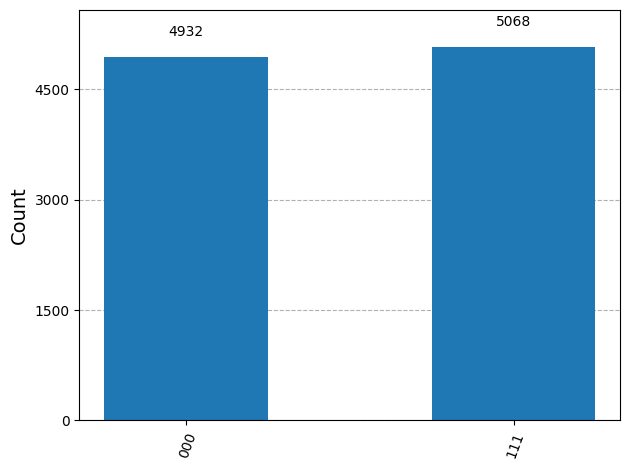

In [8]:
qc_measured = qc.copy()
qc_measured.measure(range(N_QUBITS), range(N_QUBITS))

sim = AerSimulator(seed_simulator=SEED)
job = sim.run(qc_measured, shots=SHOTS, seed_simulator=SEED)
result = job.result()
counts = result.get_counts()

fig2 = plot_histogram(counts)
fig2.savefig("ghz_state_qiskit_histogram.png", bbox_inches="tight")
fig2

In [9]:
sampled_probs = {bs: round(c / SHOTS, 4) for bs, c in counts.items()}
sampled_probs = dict(sorted(sampled_probs.items()))
print(f"Sampled probabilities ({SHOTS} shots, seed={SEED}):")
print(sampled_probs)

Sampled probabilities (10000 shots, seed=42):
{'000': 0.4932, '111': 0.5068}


## 6. Circuit resource counts

In [10]:
print(f"Depth: {qc_measured.depth()}")
print(f"Gate/operation count: {qc_measured.size()}")

Depth: 4
Gate/operation count: 6


## 7. Convention notes

In [11]:
print("Bit ordering: Qiskit's Statevector and get_counts() both natively use qubit 0 as the")
print("rightmost (least-significant) bit of the printed bitstring, matching this notebook's")
print("SETUP convention exactly -> NO reversal applied.")
print()
print("Global phase: normalized by finding the first nonzero amplitude in ascending-bitstring")
print("order and rotating the whole statevector so that amplitude becomes real and positive.")
print("For the GHZ state this is a no-op -- the |000> and |111> amplitudes are already real and")
print("positive (1/sqrt(2) each).")
print()
print("Entanglement check: unlike the Bell pair, this is genuine 3-body (GHZ-type) entanglement --")
print("no two of the three qubits can be described independently of the third. Measuring any single")
print("qubit collapses all three to a definite, perfectly correlated outcome.")

Bit ordering: Qiskit's Statevector and get_counts() both natively use qubit 0 as the
rightmost (least-significant) bit of the printed bitstring, matching this notebook's
SETUP convention exactly -> NO reversal applied.

Global phase: normalized by finding the first nonzero amplitude in ascending-bitstring
order and rotating the whole statevector so that amplitude becomes real and positive.
For the GHZ state this is a no-op -- the |000> and |111> amplitudes are already real and
positive (1/sqrt(2) each).

Entanglement check: unlike the Bell pair, this is genuine 3-body (GHZ-type) entanglement --
no two of the three qubits can be described independently of the third. Measuring any single
qubit collapses all three to a definite, perfectly correlated outcome.


## Final result (for diffing against the CUDA-Q version)

In [12]:
QISKIT_RESULT = exact_probs
print("QISKIT_RESULT =", QISKIT_RESULT)

QISKIT_RESULT = {'000': np.float64(0.5), '001': np.float64(0.0), '010': np.float64(0.0), '011': np.float64(0.0), '100': np.float64(0.0), '101': np.float64(0.0), '110': np.float64(0.0), '111': np.float64(0.5)}
